# Camelyon17-WILDS: Dataset Exploration

ELE680 – Tumor Detection across Hospitals

This notebook explores dataset size, tumor labels, hospital distributions, official WILDS splits, and tissue images.

In [1]:
import pandas as pd

DATA_DIR = '/mnt/beegfs/scratch/camelyon17/data/camelyon17_v1.0'
metadata = pd.read_csv(f'{DATA_DIR}/metadata.csv')

print('Total image patches:', len(metadata))
print()
print('Normal (0) and tumor (1) patches:')
print(metadata['tumor'].value_counts().sort_index())

Total image patches: 455954

Normal (0) and tumor (1) patches:
tumor
0    227977
1    227977
Name: count, dtype: int64


## Hospital distribution

Count image patches from each hospital and compare normal and tumor labels. Each center represents a hospital in the Camelyon17 dataset.

In [2]:
print("Images per hospital:")
print(metadata["center"].value_counts().sort_index())

print("\nNormal and tumor patches per hospital:")
print(pd.crosstab(metadata["center"], metadata["tumor"]))

Images per hospital:
center
0     59436
1     34904
2     85054
3    129838
4    146722
Name: count, dtype: int64

Normal and tumor patches per hospital:
tumor       0      1
center              
0       29718  29718
1       17452  17452
2       42527  42527
3       64919  64919
4       73361  73361


## Visualizing hospital distribution

This bar chart shows the number of image patches contributed by each hospital.

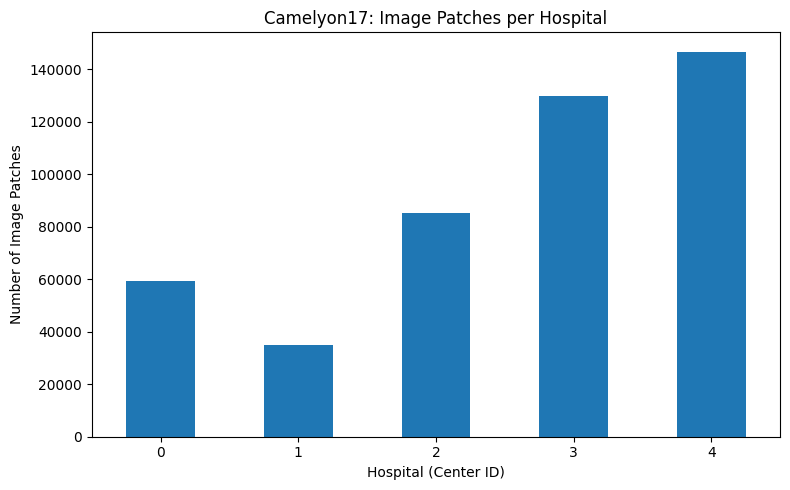

In [3]:
import matplotlib.pyplot as plt

hospital_counts = metadata["center"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
hospital_counts.plot(kind="bar")
plt.title("Camelyon17: Image Patches per Hospital")
plt.xlabel("Hospital (Center ID)")
plt.ylabel("Number of Image Patches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Official WILDS dataset splits

We use the official hospital-based splits from WILDS to prevent data leakage. The ID validation split contains held-out images from training hospitals, while OOD validation and test contain images from unseen hospitals.

In [4]:
from wilds import get_dataset

wilds_dataset = get_dataset(dataset="camelyon17", root_dir="/mnt/beegfs/scratch/camelyon17/data", download=False)

for split_name in ["train", "id_val", "val", "test"]:
    subset = wilds_dataset.get_subset(split_name)
    print(f"{split_name}: {len(subset):,} images")

train: 302,436 images
id_val: 33,560 images
val: 34,904 images
test: 85,054 images


## Visualizing real tissue images

Display one normal and one tumor image from the official WILDS training split. These examples help us understand what the CNN receives as input.

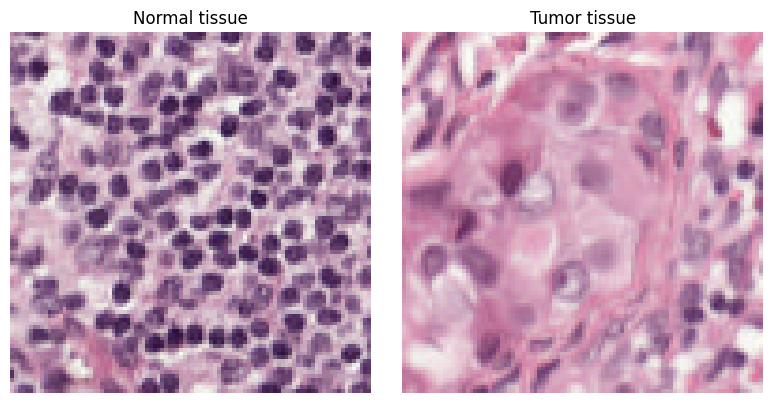

In [5]:
import matplotlib.pyplot as plt

# Select examples using labels before loading images.
train_indices = (wilds_dataset.split_array == wilds_dataset.split_dict["train"]).nonzero()[0]
labels = wilds_dataset.y_array[train_indices]

normal_index = int(train_indices[(labels == 0).nonzero()[0][0]])
tumor_index = int(train_indices[(labels == 1).nonzero()[0][0]])

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, index, title in zip(axes, [normal_index, tumor_index], ["Normal tissue", "Tumor tissue"]):
    image, label, metadata_row = wilds_dataset[index]
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()
